# GBDT 와 SHAP 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week07/gbdt_shap/lab/gbdt_shap.ipynb)

작은 나무를 차례로 쌓는 부스팅, 그리고 모델의 답을 이유별로 나누는 섀플리 값.

- **파트 1**: 부스팅 직접 구현 (깊이 1 나무로 남은 오차 맞히기) → MSE 0.48 → 0.04
- **파트 2**: 타이타닉 GBDT: 학습률 · 나무 수 · 조기 종료
- **파트 3**: 두 26살 승객의 섀플리 값 직접 계산 + `shap` 으로 확인

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
from itertools import permutations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

## 파트 1. 부스팅 직접 구현

$F_0 = 0$, 그리고 매번 $F \leftarrow F + \eta\, h$ ($h$ = 남은 오차 $y - F$ 를 맞히도록 학습한 깊이 1 나무, $\eta = 0.3$).

In [ ]:
# Same toy example as the slides: 40 points on a wave
x = np.array([0.28, 0.4, 0.62, 1.16, 1.34, 1.44, 1.61, 2.03, 2.62, 2.77, 2.8, 3.03, 3.12, 3.3, 4.03, 4.09, 4.23, 4.53, 4.59, 4.85,
              5.12, 5.16, 5.29, 5.38, 5.41, 5.5, 6.13, 6.23, 7.25, 7.5, 7.54, 7.77, 7.88, 8.28, 9.17, 9.49, 9.5, 9.62, 9.7, 9.81])
y = np.array([0.3, 0.08, 0.41, 0.9, 0.74, 0.97, 1.02, 0.9, 0.37, 0.51, 0.55, 0.19, -0.18, 0.03, -0.9, -0.59, -1.16, -0.76, -1.0, -1.3,
              -1.0, -0.89, -0.77, -1.03, -1.04, -0.66, -0.27, 0.01, 1.01, 0.53, 1.01, 1.3, 0.93, 0.71, 0.44, 0.0, 0.14, -0.28, -0.64, -0.4])

def boost(x, y, n_trees, lr):
    F = np.full(len(y), y.mean())                         # start from the mean
    trees, mse = [], []
    for _ in range(n_trees):
        residual = None  # TODO: what is still wrong
        h = DecisionTreeRegressor(max_depth=1).fit(x.reshape(-1, 1), residual)
        F = None  # TODO: add the new tree, scaled by lr
        trees.append(h); mse.append(np.mean((y - F) ** 2))
    return trees, mse

trees, mse = boost(x, y, 50, 0.3)
print({n: round(float(mse[n - 1]), 2) for n in [1, 3, 10, 50]})
xs = np.linspace(0, 10, 300).reshape(-1, 1)
pred = y.mean() + 0.3 * sum(t.predict(xs) for t in trees)
plt.scatter(x, y, color="k"); plt.plot(xs, pred, "r"); plt.title("50 stumps"); plt.show()

**예상 결과**

```
{1: 0.48, 3: 0.39, 10: 0.22, 50: 0.04}
```

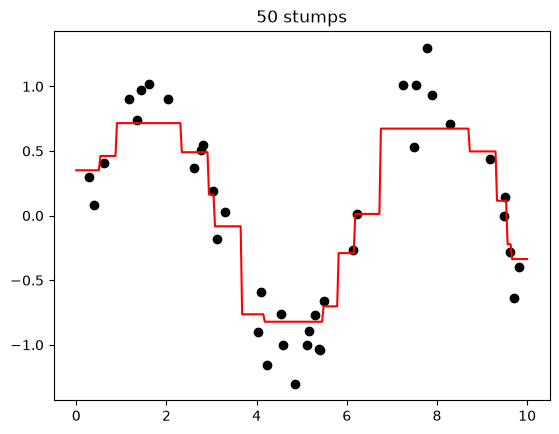

## 파트 2. 타이타닉 GBDT

OpenML 의 타이타닉 1,309명. 특징 5개 (등급, 여성 여부, 나이, 요금, 가족 수). 처음 실행하면 내려받는다.

In [ ]:
from sklearn.datasets import fetch_openml
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
f = fetch_openml("titanic", version=1, as_frame=True).frame
X = pd.DataFrame({"pclass": f.pclass.astype(int), "female": (f.sex == "female").astype(int),
                  "age": f.age.astype(float).fillna(f.age.astype(float).median()),
                  "fare": f.fare.astype(float).fillna(f.fare.astype(float).median()),
                  "family": f.sibsp.astype(int) + f.parch.astype(int)})
y = f.survived.astype(int).to_numpy()
print(X.shape, "survival rate", round(y.mean(), 3))
cv = StratifiedKFold(5, shuffle=True, random_state=0)
for lr, n in [(0.5, 200), (0.05, 200), (0.05, 2000)]:
    acc = cross_val_score(GradientBoostingClassifier(n_estimators=n, max_depth=3, learning_rate=lr, random_state=0), X, y, cv=cv).mean()
    print(f"learning rate {lr:4}, {n:4d} trees: CV accuracy {acc:.3f}")

**예상 결과**

```
(1309, 5) survival rate 0.382
learning rate  0.5,  200 trees: CV accuracy 0.784
learning rate 0.05,  200 trees: CV accuracy 0.807
learning rate 0.05, 2000 trees: CV accuracy 0.788
```

In [ ]:
# Early stopping: hold out 10% inside and stop when it stops improving for 20 rounds
es = GradientBoostingClassifier(n_estimators=2000, max_depth=3, learning_rate=0.05, validation_fraction=0.1,
                                n_iter_no_change=20, random_state=0)
acc = cross_val_score(es, X, y, cv=cv).mean()
print(f"with early stopping: CV accuracy {acc:.3f}, trees used on the full data: {es.fit(X, y).n_estimators_}")

**예상 결과**

```
with early stopping: CV accuracy 0.813, trees used on the full data: 145
```

## 파트 3. 섀플리 값 직접 계산

정보 셋: 성별 (`female`) · 등급 (`pclass`) · 나머지 (`age`, `fare`, `family`). 모르는 정보는 그 칸에 모든 승객의 실제 값을 넣어 보고 평균. 순서 6가지에서 '오른 만큼' 을 평균한다.

In [ ]:
M = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=0).fit(X, y)
TEAM = {"sex": ["female"], "class": ["pclass"], "rest": ["age", "fare", "family"]}

def value(model, X, i, known):
    Z = X.copy()
    for g in known:
        for c in TEAM[g]:
            Z[c] = X.iloc[i][c]                           # fix what we know to passenger i's value
    return model.predict_proba(Z)[:, 1].mean() * 100     # unknown columns keep everyone's values -> average

def shapley(model, X, i):
    phi = {g: 0.0 for g in TEAM}
    orders = list(permutations(TEAM))
    for order in orders:
        known = []
        for g in order:
            before = value(model, X, i, known)
            known = known + [g]
            phi[g] += None  # TODO: how much g raised the probability
    return {g: v / len(orders) for g, v in phi.items()}

for i in [13, 609]:                                       # both 26 years old
    p = M.predict_proba(X.iloc[[i]])[0, 1] * 100
    phi = shapley(M, X, i)
    print(X.iloc[i].to_dict(), f"-> {p:.1f}%")
    print("   base", round(value(M, X, i, []), 1), {g: round(float(v), 1) for g, v in phi.items()}, " sum check:", round(value(M, X, i, []) + sum(phi.values()), 1))

**예상 결과**

```
{'pclass': 1.0, 'female': 1.0, 'age': 26.0, 'fare': 78.85, 'family': 0.0} -> 96.0%
   base 38.2 {'sex': 34.0, 'class': 22.6, 'rest': 1.3}  sum check: 96.0
{'pclass': 3.0, 'female': 0.0, 'age': 26.0, 'fare': 8.05, 'family': 0.0} -> 12.7%
   base 38.2 {'sex': -14.8, 'class': -7.6, 'rest': -3.2}  sum check: 12.7
```

In [ ]:
try:
    import shap
except ImportError:
    import subprocess, sys; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"]); import shap
explainer = shap.TreeExplainer(M, data=shap.sample(X, 200, random_state=0), model_output="probability")
sv = explainer.shap_values(X) * 100
for i in [13, 609]:
    print(i, {c: float(v) for c, v in zip(X.columns, sv[i].round(1))})
print("mean |SHAP| (%p):", {c: float(v) for c, v in zip(X.columns, np.abs(sv).mean(0).round(1))})

**예상 결과**

```
13 {'pclass': 19.7, 'female': 35.0, 'age': 0.6, 'fare': 3.8, 'family': 0.7}
609 {'pclass': -7.6, 'female': -9.5, 'age': -4.6, 'fare': -2.6, 'family': 0.7}
mean |SHAP| (%p): {'pclass': 10.6, 'female': 19.3, 'age': 6.7, 'fare': 4.9, 'family': 1.6}
```

**확인 질문**
1. 파트 1 에서 학습률을 1.0 과 0.05 로 바꾸면 50그루 뒤 MSE 는? 학습 데이터 MSE 만 보고 학습률을 고르면 어떤 문제가 생길까?
2. 파트 2 에서 학습률 0.5 와 0.05 중 어느 쪽이 나았나? 나무를 2000그루로 늘리면?
3. 파트 3 의 직접 계산 (팀 3개) 과 `shap` 의 값 (특징 5개) 을 비교하자. 성별 · 등급의 몫은 비슷한가?
4. 요금(`fare`) 과 등급(`pclass`) 은 함께 움직인다. 이것이 SHAP 해석에 어떤 영향을 줄까?

데이터 출처: Titanic (OpenML id 40945 / titanic v1; Vanderbilt Biostatistics titanic3).